In [1]:
from pathlib import Path
import sys

current = Path.cwd().resolve()

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if (folder / "inner maximization").is_dir()
        and (folder / "outer minimization").is_dir()
    ),
    None,
)

if root is None:
    raise FileNotFoundError(
        f"Could not find awdro above the current directory: {current}"
    )

for folder in [
    root,
    root / "path simulation",
    root / "hedging",
    root / "inner maximization",
    root / "outer minimization",
]:
    sys.path.insert(0, str(folder))

print("Project root:", root)

Project root: /Users/jacve/Git/awdro


In [2]:
from pathlib import Path
import sys

import numpy as np
import torch

current = Path.cwd().resolve()

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if (folder / "inner maximization").is_dir()
        and (folder / "outer minimization").is_dir()
    ),
    None,
)

if root is None:
    raise FileNotFoundError("Open this notebook inside awdro.")

for folder in [
    root,
    root / "path simulation",
    root / "hedging",
    root / "inner maximization",
    root / "outer minimization",
]:
    sys.path.insert(0, str(folder))

from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver
from hedging.strategies import ConstantHedge

In [3]:
model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)

trading_times = np.array([0.0, 0.5, 1.0])
budget = 1.0
penalty = 2.0

discretization = {
    "reference_branches": 2,
    "seed": 42,
}


def call_payoff(paths):
    return torch.clamp(paths[:, -1, 0] - 100.0, min=0.0)


problem = SuperhedgingProblem(
    payoff=call_payoff,
    trading_times=trading_times,
)

nonrectangular_solver = NonrectangularSolver(
    reference_model=model,
    trading_times=trading_times,
    budget=budget,
    discretization=discretization,
)

# This object supplies the ORIGINAL causal transport constraints.
# Its rectangular solve method is not used in the CVXPY formulation.
transport_model = RectangularSolver(
    reference_model=model,
    trading_times=trading_times,
    budget=budget,
    discretization=discretization,
)

outer_solver = RelaxedSuperhedgingSolver(
    problem=problem,
    inner_solver=nonrectangular_solver,
    penalty=penalty,
)

# Verify matching reference discretizations.
np.testing.assert_array_equal(
    np.asarray([
        node["state"] for node in nonrectangular_solver.reference_nodes
    ]),
    np.asarray([
        node["state"] for node in transport_model.reference_nodes
    ]),
)

for t in range(len(trading_times)):
    np.testing.assert_array_equal(
        nonrectangular_solver.adversarial_candidates[t],
        transport_model.adversarial_candidates[t],
    )

print("Discretizations match.")

Discretizations match.


In [4]:
capital_bounds = (0.0, 50.0)
holding_bounds = (-2.0, 2.0)

result = outer_solver.solve_constant_hedge_nonrectangular(
    transport_model=transport_model,
    capital_bounds=capital_bounds,
    holding_bounds=holding_bounds,
)

capital = result["capital"]
holding = result["holding"]
hedge = ConstantHedge(holding)

tolerance = 1e-4

assert np.isfinite(list(result.values())).all()
assert capital_bounds[0] - tolerance <= capital <= capital_bounds[1] + tolerance
assert holding_bounds[0] - tolerance <= holding <= holding_bounds[1] + tolerance


def optimized_loss(paths):
    return problem.shortfall(paths, capital, hedge)


checked_shortfall = float(
    nonrectangular_solver.solve(optimized_loss)["value"]
)
checked_objective = capital + penalty * checked_shortfall

np.testing.assert_allclose(
    result["worst_case_shortfall"],
    checked_shortfall,
    rtol=1e-5,
    atol=tolerance,
)

np.testing.assert_allclose(
    result["value"],
    checked_objective,
    rtol=1e-5,
    atol=tolerance,
)

print(f"Capital:                  {capital:.8f}")
print(f"Constant holding:         {holding:.8f}")
print(f"CVXPY objective:          {result['value']:.8f}")
print(f"DP-checked objective:     {checked_objective:.8f}")
print(f"Worst-case shortfall:     {checked_shortfall:.8f}")
print("Independent objective check passed.")

Capital:                  0.00000000
Constant holding:         1.00000000
CVXPY objective:          2.76602171
DP-checked objective:     2.76602192
Worst-case shortfall:     1.38301096
Independent objective check passed.


In [5]:
zero_hedge_result = outer_solver.solve_capital(
    H=ConstantHedge(0.0),
    capital_bounds=capital_bounds,
)

comparison_tolerance = 1e-4 * max(
    1.0,
    abs(result["value"]),
    abs(zero_hedge_result["value"]),
)

assert result["value"] <= (
    zero_hedge_result["value"] + comparison_tolerance
)

print(f"Zero-hedge objective:     {zero_hedge_result['value']:.8f}")
print(f"Optimized-hedge objective: {result['value']:.8f}")
print("Zero-hedge comparison passed.")

Zero-hedge objective:     17.99729970
Optimized-hedge objective: 2.76602171
Zero-hedge comparison passed.


In [6]:
class FlatTestModel:
    s0 = 100.0
    v0 = 0.0

    def is_valid_state(self, state):
        state = np.asarray(state, dtype=float)
        return (
            state.shape == (2,)
            and np.isfinite(state).all()
            and state[0] > 0
            and state[1] >= 0
        )

    def step(self, state, dt, rng):
        return np.asarray(state, dtype=float).copy()


def constant_payoff(paths):
    return torch.full(
        (paths.shape[0],),
        10.0,
        dtype=paths.dtype,
        device=paths.device,
    )


flat_model = FlatTestModel()
flat_times = np.array([0.0, 1.0])
flat_discretization = {"reference_branches": 1, "seed": 42}

flat_problem = SuperhedgingProblem(
    payoff=constant_payoff,
    trading_times=flat_times,
)

flat_inner = NonrectangularSolver(
    flat_model, flat_times, 0.0, flat_discretization
)
flat_transport = RectangularSolver(
    flat_model, flat_times, 0.0, flat_discretization
)

flat_outer = RelaxedSuperhedgingSolver(
    problem=flat_problem,
    inner_solver=flat_inner,
    penalty=2.0,
)

for bounds, expected_capital, expected_value in [
    ((0.0, 20.0), 10.0, 10.0),  # Interior optimum
    ((0.0, 8.0), 8.0, 12.0),    # Upper-bound optimum
    ((12.0, 20.0), 12.0, 12.0),  # Lower-bound optimum
]:
    answer = flat_outer.solve_constant_hedge_nonrectangular(
        transport_model=flat_transport,
        capital_bounds=bounds,
        holding_bounds=(-2.0, 2.0),
    )

    np.testing.assert_allclose(
        [answer["capital"], answer["value"]],
        [expected_capital, expected_value],
        rtol=0.0,
        atol=1e-4,
    )

    print(f"Bounds {bounds}: passed.")

print("Known-optimum checks passed.")

Bounds (0.0, 20.0): passed.
Bounds (0.0, 8.0): passed.
Bounds (12.0, 20.0): passed.
Known-optimum checks passed.


In [7]:
from pathlib import Path
import sys

import numpy as np
import torch

current = Path.cwd().resolve()

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if (folder / "inner maximization").is_dir()
        and (folder / "outer minimization").is_dir()
    ),
    None,
)

if root is None:
    raise FileNotFoundError("Open this notebook inside awdro.")

for folder in [
    root,
    root / "hedging",
    root / "path simulation",
    root / "inner maximization",
    root / "outer minimization",
]:
    sys.path.insert(0, str(folder))

from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from FirstOrderSensitivitySolver import FirstOrderSensitivitySolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver
from hedging.strategies import ConstantHedge

model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)

times = np.array([0.0, 0.5, 1.0])
discretization = {"reference_branches": 2, "seed": 42}
penalty = 2.0


def call_payoff(paths):
    return torch.clamp(paths[:, -1, 0] - 100.0, min=0.0)


problem = SuperhedgingProblem(
    payoff=call_payoff,
    trading_times=times,
)

In [8]:
capital_bounds = (0.0, 50.0)
holding_bounds = (-2.0, 2.0)

for budget in [0.0, 0.5, 1.0]:
    rectangular = RectangularSolver(
        model, times, budget, discretization
    )
    nonrectangular = NonrectangularSolver(
        model, times, budget, discretization
    )

    np.testing.assert_array_equal(
        np.asarray([node["state"] for node in rectangular.reference_nodes]),
        np.asarray([node["state"] for node in nonrectangular.reference_nodes]),
    )

    for t in range(len(times)):
        np.testing.assert_array_equal(
            rectangular.adversarial_candidates[t],
            nonrectangular.adversarial_candidates[t],
        )

    outer = RelaxedSuperhedgingSolver(
        problem=problem,
        inner_solver=nonrectangular,
        penalty=penalty,
    )

    rect_result = outer.solve_constant_hedge_rectangular(
        rectangular,
        capital_bounds,
        holding_bounds,
    )

    nonrect_result = outer.solve_constant_hedge_nonrectangular(
        rectangular,
        capital_bounds,
        holding_bounds,
    )

    capital = rect_result["capital"]
    hedge = ConstantHedge(rect_result["holding"])

    loss_fn = lambda paths: problem.shortfall(paths, capital, hedge)

    # Independently evaluate the rectangular optimizer's solution.
    dp_shortfall = float(rectangular.solve(loss_fn)["value"])
    dp_objective = capital + penalty * dp_shortfall

    np.testing.assert_allclose(
        rect_result["worst_case_shortfall"],
        dp_shortfall,
        rtol=1e-5,
        atol=1e-4,
    )

    np.testing.assert_allclose(
        rect_result["value"],
        dp_objective,
        rtol=1e-5,
        atol=1e-4,
    )

    tolerance = 1e-4 * max(
        1.0,
        abs(rect_result["value"]),
        abs(nonrect_result["value"]),
    )

    # Inclusion of ambiguity sets survives minimization over
    # the same capital and holding domain.
    assert rect_result["value"] >= nonrect_result["value"] - tolerance

    assert capital_bounds[0] - tolerance <= capital <= capital_bounds[1] + tolerance
    assert (
        holding_bounds[0] - tolerance
        <= rect_result["holding"]
        <= holding_bounds[1] + tolerance
    )

    if budget == 0:
        np.testing.assert_allclose(
            rect_result["value"],
            nonrect_result["value"],
            rtol=1e-5,
            atol=1e-4,
        )

    print(
        f"budget={budget:.2f}  "
        f"rectangular={rect_result['value']:.8f}  "
        f"nonrectangular={nonrect_result['value']:.8f}  "
        f"gap={rect_result['value'] - nonrect_result['value']:.8f}"
    )

print("Rectangular outer/inner consistency checks passed.")

budget=0.00  rectangular=2.66710650  nonrectangular=2.66710649  gap=0.00000002
budget=0.50  rectangular=2.74718127  nonrectangular=2.69183529  gap=0.05534598
budget=1.00  rectangular=2.97757437  nonrectangular=2.76602171  gap=0.21155266
Rectangular outer/inner consistency checks passed.


In [9]:
class FlatTestModel:
    s0 = 100.0
    v0 = 0.0

    def is_valid_state(self, state):
        state = np.asarray(state, dtype=float)
        return (
            state.shape == (2,)
            and np.isfinite(state).all()
            and state[0] > 0
            and state[1] >= 0
        )

    def step(self, state, dt, rng):
        return np.asarray(state, dtype=float).copy()


def constant_payoff(paths):
    return torch.full(
        (paths.shape[0],),
        10.0,
        dtype=paths.dtype,
        device=paths.device,
    )


flat_times = np.array([0.0, 1.0])

flat_problem = SuperhedgingProblem(
    payoff=constant_payoff,
    trading_times=flat_times,
)

# Test both the zero-budget shortcut and conditional-dual formulation.
for budget in [0.0, 1.0]:
    flat_transport = RectangularSolver(
        FlatTestModel(),
        flat_times,
        budget,
        {"reference_branches": 1, "seed": 42},
    )

    flat_outer = RelaxedSuperhedgingSolver(
        flat_problem,
        flat_transport,
        penalty=2.0,
    )

    for bounds, expected in [
        ((0.0, 20.0), [10.0, 10.0]),
        ((0.0, 8.0), [8.0, 12.0]),
        ((12.0, 20.0), [12.0, 12.0]),
    ]:
        result = flat_outer.solve_constant_hedge_rectangular(
            flat_transport,
            bounds,
            (-2.0, 2.0),
        )

        np.testing.assert_allclose(
            [result["capital"], result["value"]],
            expected,
            rtol=0.0,
            atol=1e-4,
        )

print("Rectangular known-optimum checks passed.")

Rectangular known-optimum checks passed.


In [10]:
reference_paths = model.simulate_paths(
    n_paths=256,
    n_steps=2,
    horizon=1.0,
    seed=123,
)


def make_sensitivity_solver(budget):
    return FirstOrderSensitivitySolver(
        reference_paths=reference_paths,
        geometry="euclidean",
        transport="ordinary",
        p=2,
        conditional_estimator=None,
        budget=budget,
    )


def linear_loss(paths):
    return 2.0 * paths[:, -1, 0] + 3.0 * paths[:, -1, 1]


sensitivity_solver = make_sensitivity_solver(0.1)

gradients = (
    sensitivity_solver.path_gradients(linear_loss)
    .detach()
    .cpu()
    .numpy()
)

expected_gradients = np.zeros_like(reference_paths)
expected_gradients[:, -1, 0] = 2.0
expected_gradients[:, -1, 1] = 3.0

np.testing.assert_allclose(
    gradients,
    expected_gradients,
    rtol=0.0,
    atol=1e-10,
)

coefficient = float(
    sensitivity_solver.sensitivity(linear_loss).detach().cpu()
)

np.testing.assert_allclose(
    coefficient,
    np.sqrt(13.0),
    rtol=0.0,
    atol=1e-10,
)

print("Analytical path-gradient and sensitivity checks passed.")

Analytical path-gradient and sensitivity checks passed.


In [11]:
def stock_payoff(paths):
    return paths[:, -1, 0]


stock_problem = SuperhedgingProblem(
    payoff=stock_payoff,
    trading_times=times,
)

expected_nominal = float(np.mean(
    0.75 * reference_paths[:, -1, 0]
    + 0.25 * reference_paths[:, 0, 0]
))

for budget in [0.0, 0.1, 0.5]:
    sensitivity_solver = make_sensitivity_solver(budget)

    sensitivity_outer = RelaxedSuperhedgingSolver(
        problem=stock_problem,
        inner_solver=sensitivity_solver,
        penalty=2.0,
    )

    result = sensitivity_outer.evaluate_constant_hedge_first_order(
        sensitivity_solver=sensitivity_solver,
        capital=0.0,
        holding=0.25,
    )

    expected_shortfall = expected_nominal + budget * 0.75

    np.testing.assert_allclose(
        result["nominal_shortfall"],
        expected_nominal,
        rtol=0.0,
        atol=1e-10,
    )

    np.testing.assert_allclose(
        result["approximate_worst_case_shortfall"],
        expected_shortfall,
        rtol=0.0,
        atol=1e-10,
    )

    np.testing.assert_allclose(
        result["value"],
        2.0 * expected_shortfall,
        rtol=0.0,
        atol=1e-10,
    )

    if budget > 0:
        np.testing.assert_allclose(
            result["sensitivity"],
            0.75,
            rtol=0.0,
            atol=1e-10,
        )
    else:
        assert result["sensitivity"] is None

print("First-order outer-evaluation checks passed.")

First-order outer-evaluation checks passed.


In [12]:
import pandas as pd

budgets = [0.0, 0.5, 1.0, 2.0]
seeds = [42, 43, 44]

capital_bounds = (0.0, 50.0)
holding_bounds = (-2.0, 2.0)

records = []

for seed in seeds:
    for budget in budgets:
        settings = {
            "reference_branches": 2,
            "seed": seed,
        }

        rectangular = RectangularSolver(
            model, times, budget, settings
        )
        nonrectangular = NonrectangularSolver(
            model, times, budget, settings
        )

        # Ensure both methods use the same reference tree and candidates.
        np.testing.assert_array_equal(
            np.asarray([
                node["state"] for node in rectangular.reference_nodes
            ]),
            np.asarray([
                node["state"] for node in nonrectangular.reference_nodes
            ]),
        )

        for t in range(len(times)):
            np.testing.assert_array_equal(
                rectangular.adversarial_candidates[t],
                nonrectangular.adversarial_candidates[t],
            )

        outer = RelaxedSuperhedgingSolver(
            problem=problem,
            inner_solver=nonrectangular,
            penalty=penalty,
        )

        nr = outer.solve_constant_hedge_nonrectangular(
            rectangular,
            capital_bounds,
            holding_bounds,
        )

        rect = outer.solve_constant_hedge_rectangular(
            rectangular,
            capital_bounds,
            holding_bounds,
        )

        gap = rect["value"] - nr["value"]

        tolerance = 1e-4 * max(
            1.0, abs(rect["value"]), abs(nr["value"])
        )

        assert gap >= -tolerance, (
            f"Negative gap beyond tolerance: seed={seed}, budget={budget}"
        )

        if budget == 0:
            np.testing.assert_allclose(
                rect["value"],
                nr["value"],
                rtol=1e-5,
                atol=1e-4,
            )

        records.append({
            "seed": seed,
            "budget": budget,
            "nonrectangular_value": nr["value"],
            "rectangular_value": rect["value"],
            "gap": gap,
            "nonrectangular_capital": nr["capital"],
            "rectangular_capital": rect["capital"],
            "nonrectangular_holding": nr["holding"],
            "rectangular_holding": rect["holding"],
            "nonrectangular_shortfall": nr["worst_case_shortfall"],
            "rectangular_shortfall": rect["worst_case_shortfall"],
        })

        print(
            f"seed={seed}, budget={budget:.2f}: "
            f"nonrectangular={nr['value']:.6f}, "
            f"rectangular={rect['value']:.6f}, "
            f"gap={gap:.6f}"
        )

results = pd.DataFrame(records)
display(results)

seed=42, budget=0.00: nonrectangular=2.667106, rectangular=2.667107, gap=0.000000
seed=42, budget=0.50: nonrectangular=2.691835, rectangular=2.747181, gap=0.055346
seed=42, budget=1.00: nonrectangular=2.766022, rectangular=2.977574, gap=0.211553
seed=42, budget=2.00: nonrectangular=3.062767, rectangular=3.779891, gap=0.717123
seed=43, budget=0.00: nonrectangular=9.228928, rectangular=9.228928, gap=-0.000000
seed=43, budget=0.50: nonrectangular=9.279659, rectangular=9.290496, gap=0.010837
seed=43, budget=1.00: nonrectangular=9.361371, rectangular=9.361371, gap=0.000000
seed=43, budget=2.00: nonrectangular=9.361371, rectangular=9.361371, gap=-0.000000
seed=44, budget=0.00: nonrectangular=1.421168, rectangular=1.421168, gap=-0.000000
seed=44, budget=0.50: nonrectangular=1.511712, rectangular=1.523166, gap=0.011454
seed=44, budget=1.00: nonrectangular=1.783343, rectangular=1.824097, gap=0.040753
seed=44, budget=2.00: nonrectangular=2.405469, rectangular=2.405469, gap=0.000000


,seed,budget,nonrectangular_value,rectangular_value,gap,nonrectangular_capital,rectangular_capital,nonrectangular_holding,rectangular_holding,nonrectangular_shortfall,rectangular_shortfall
0,42,0.0,2.667106,2.667107,1.654783e-08,1.613244e-10,1.404397e-08,1.000000e+00,1.000000e+00,1.333553e+00,1.333553e+00
1,42,0.5,2.691835,2.747181,5.534598e-02,4.077382e-10,4.823423e-10,1.000000e+00,1.000000e+00,1.345918e+00,1.373591e+00
2,42,1.0,2.766022,2.977574,2.115527e-01,1.209003e-09,2.643661e-11,1.000000e+00,1.000000e+00,1.383011e+00,1.488787e+00
3,42,2.0,3.062767,3.779891,7.171232e-01,2.149561e-10,6.303224e-11,1.000000e+00,1.000000e+00,1.531384e+00,1.889945e+00
4,43,0.0,9.228928,9.228928,-6.435279e-10,7.209197e+00,7.209197e+00,6.401993e-01,6.401993e-01,1.009865e+00,1.009865e+00
5,43,0.5,9.279659,9.290496,1.083721e-02,7.209197e+00,7.209197e+00,6.401993e-01,6.401993e-01,1.035231e+00,1.040650e+00
6,43,1.0,9.361371,9.361371,1.600924e-10,9.361371e+00,9.361371e+00,5.327873e-01,5.327873e-01,3.192009e-09,6.476823e-09
7,43,2.0,9.361371,9.361371,-1.949179e-10,9.361371e+00,9.361371e+00,5.327873e-01,5.327873e-01,9.550783e-10,2.915189e-10
8,44,0.0,1.421168,1.421168,-2.167248e-09,1.412326e-10,8.977922e-11,-4.943944e-10,9.007702e-12,7.105842e-01,7.105842e-01
9,44,0.5,1.511712,1.523166,1.145399e-02,1.073629e-10,2.270020e-10,-1.694790e-11,-1.564759e-11,7.558561e-01,7.615831e-01


In [13]:
summary = (
    results.groupby("budget", as_index=False)
    .agg(
        nonrectangular_mean=("nonrectangular_value", "mean"),
        rectangular_mean=("rectangular_value", "mean"),
        gap_mean=("gap", "mean"),
        gap_std=("gap", "std"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
    )
)

display(summary)

,budget,nonrectangular_mean,rectangular_mean,gap_mean,gap_std,gap_min,gap_max
0,0.0,4.439067,4.439067,4.579017e-09,1.039326e-08,-2.167248e-09,1.654783e-08
1,0.5,4.494402,4.520281,2.587906e-02,2.552096e-02,1.083721e-02,5.534598e-02
2,1.0,4.636912,4.721014,8.410205e-02,1.122406e-01,1.600924e-10,2.115527e-01
3,2.0,4.943202,5.182244,2.390411e-01,4.140313e-01,-1.949179e-10,7.171232e-01


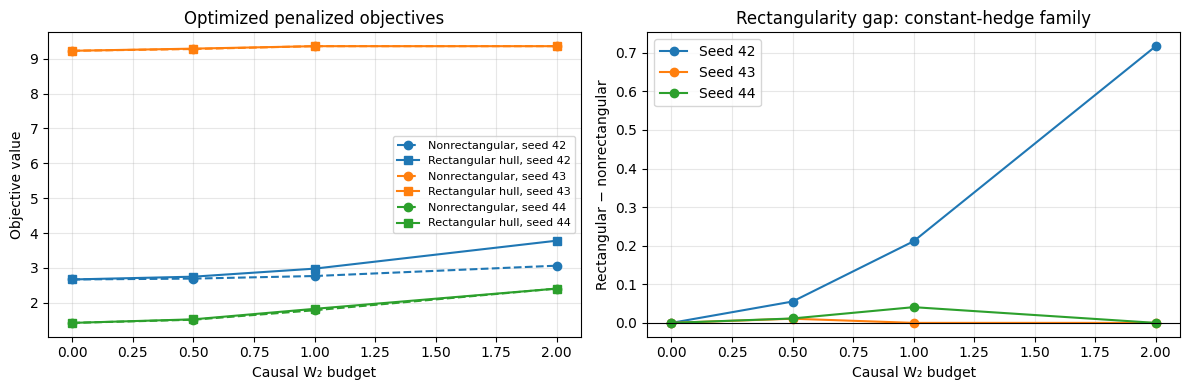

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for seed, group in results.groupby("seed"):
    group = group.sort_values("budget")

    line = axes[0].plot(
        group["budget"],
        group["nonrectangular_value"],
        marker="o",
        linestyle="--",
        label=f"Nonrectangular, seed {seed}",
    )[0]

    axes[0].plot(
        group["budget"],
        group["rectangular_value"],
        marker="s",
        color=line.get_color(),
        label=f"Rectangular hull, seed {seed}",
    )

    axes[1].plot(
        group["budget"],
        group["gap"],
        marker="o",
        label=f"Seed {seed}",
    )

axes[0].set_title("Optimized penalized objectives")
axes[0].set_xlabel("Causal W₂ budget")
axes[0].set_ylabel("Objective value")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title("Rectangularity gap: constant-hedge family")
axes[1].set_xlabel("Causal W₂ budget")
axes[1].set_ylabel("Rectangular − nonrectangular")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
bound_tolerance = 1e-4

for prefix in ["nonrectangular", "rectangular"]:
    capital_column = results[f"{prefix}_capital"]
    holding_column = results[f"{prefix}_holding"]

    results[f"{prefix}_at_bound"] = (
        np.isclose(
            capital_column, capital_bounds[0],
            rtol=0.0, atol=bound_tolerance,
        )
        | np.isclose(
            capital_column, capital_bounds[1],
            rtol=0.0, atol=bound_tolerance,
        )
        | np.isclose(
            holding_column, holding_bounds[0],
            rtol=0.0, atol=bound_tolerance,
        )
        | np.isclose(
            holding_column, holding_bounds[1],
            rtol=0.0, atol=bound_tolerance,
        )
    )

display(results[[
    "seed",
    "budget",
    "nonrectangular_at_bound",
    "rectangular_at_bound",
]])

,seed,budget,nonrectangular_at_bound,rectangular_at_bound
0,42,0.0,True,True
1,42,0.5,True,True
2,42,1.0,True,True
3,42,2.0,True,True
4,43,0.0,False,False
5,43,0.5,False,False
6,43,1.0,False,False
7,43,2.0,False,False
8,44,0.0,True,True
9,44,0.5,True,True
